# Notebook 4 – Data Augmentation



In [2]:
import time
import numpy as np
import torch
from torch import nn
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.14.0+cpu | device: cpu


## Concept and simple example
Augmentation creates additional views of existing labeled training examples. Useful candidates include horizontal/vertical flips, rotation, random crop, resize, translation, brightness/contrast changes, and random affine transforms. It may reduce overfitting and improve generalization when transforms resemble real variation; it may harm performance when a transform changes the class or removes identifying evidence.

A vertical flip may be valid for some microscopy images but invalid for upright apparel. Horizontal flips can reverse text or laterality. Pick transformations from domain knowledge.

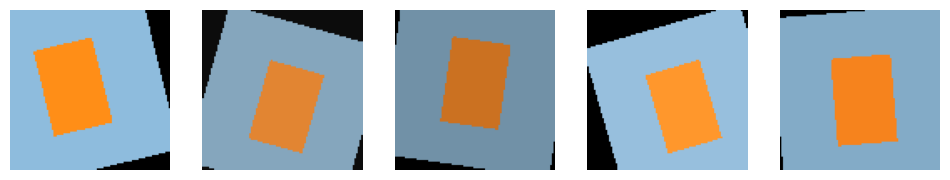

paired training sizes: 60000 60000


In [3]:
from PIL import Image, ImageDraw
from torchvision import transforms
import matplotlib.pyplot as plt
base=Image.new('RGB',(96,96),(130,165,190)); ImageDraw.Draw(base).rectangle((32,25,64,72),fill=(230,130,40))
augment=transforms.Compose([transforms.Resize((96,96)),transforms.RandomAffine(degrees=18,translate=(.12,.12),scale=(.9,1.1)),transforms.ColorJitter(brightness=.2,contrast=.2),transforms.RandomHorizontalFlip(.5),transforms.ToTensor()])
fig,axes=plt.subplots(1,5,figsize=(12,3))
for ax in axes: ax.imshow(augment(base).permute(1,2,0)); ax.axis('off')
plt.show()
from torchvision import datasets
plain=datasets.FashionMNIST('data',train=True,download=True,transform=transforms.ToTensor())
aug_tf=transforms.Compose([transforms.RandomAffine(12,translate=(.08,.08)),transforms.RandomHorizontalFlip(.5),transforms.ToTensor()])
aug=datasets.FashionMNIST('data',train=True,download=False,transform=aug_tf)
print('paired training sizes:',len(plain),len(aug))

## Compare and interpret
Train identical fresh models with and without augmentation: same split, seed, architecture, optimizer, epochs, and batch size. Evaluate both on the same unaugmented validation set. Record training accuracy, validation accuracy, and their gap each epoch. With augmentation, training accuracy may fall while validation accuracy improves and overfitting shrinks. If both worsen, transformations may be too strong or invalid.

**Result analysis:** Explain the measured difference; do not assume augmentation helped. Fashion-MNIST is mostly upright, so avoid strong vertical flips.

## Run a controlled comparison offline
The experiment below trains the same small CNN with identical splits and settings. Only the augmented run applies small translations/rotations. Digits should not be flipped because flipping can change their labels.


In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms
import torch.nn.functional as F

d=load_digits(); images=torch.tensor(d.images,dtype=torch.float32).unsqueeze(1)/16; labels=torch.tensor(d.target,dtype=torch.long)
x_train,x_val,y_train,y_val=train_test_split(images,labels,test_size=.25,random_state=42,stratify=labels)
class DigitViews(Dataset):
 def __init__(self,x,y,augment=False): self.x=x; self.y=y; self.transform=transforms.RandomAffine(degrees=10,translate=(.08,.08)) if augment else None
 def __len__(self): return len(self.y)
 def __getitem__(self,i):
  image=self.x[i]
  if self.transform: image=self.transform(image)
  return image,self.y[i]
def make_net():
 return nn.Sequential(nn.Conv2d(1,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((2,2)),nn.Flatten(),nn.Linear(128,10)).to(device)
val_loader=DataLoader(DigitViews(x_val,y_val),batch_size=128)
def fit_variant(augment):
 torch.manual_seed(123); np.random.seed(123)
 train_loader=DataLoader(DigitViews(x_train,y_train,augment),batch_size=128,shuffle=True); model=make_net(); optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
 for epoch in range(8):
  model.train()
  for xb,yb in train_loader:
   xb,yb=xb.to(device),yb.to(device); optimizer.zero_grad(); loss=nn.functional.cross_entropy(model(xb),yb); loss.backward(); optimizer.step()
 def score(loader):
  model.eval(); good=total=0
  with torch.no_grad():
   for xb,yb in loader: good+=(model(xb.to(device)).argmax(1).cpu()==yb).sum().item(); total+=len(yb)
  return good/total
 train_eval=DataLoader(DigitViews(x_train,y_train),batch_size=128)
 return score(train_eval),score(val_loader)
for label,flag in [('without augmentation',False),('with augmentation',True)]:
 train_acc,val_acc=fit_variant(flag); print(f'{label:22} train_acc={train_acc:.3f} val_acc={val_acc:.3f} gap={train_acc-val_acc:.3f}')


without augmentation   train_acc=0.751 val_acc=0.731 gap=0.019
with augmentation      train_acc=0.730 val_acc=0.716 gap=0.014
